In [36]:

import icepyx as ipx
import numpy as np
import xarray as xr
import pandas as pd
import h5py
import os, json
from pprint import pprint
import dask.dataframe as dd
import rioxarray as rxr
import rasterio
import rasterio
from pyproj import Transformer
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.family'] = 'Arial'


In [37]:
import glob
import re
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator


from readers.add_atl08_info import add_atl08_classed_flag
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam_h5py

def read_hdf5_atl03_beam_h5py(filename, beam, verbose=False):
    """
    ATL03 原始数据读取
    Args:
        filename (str): h5文件路径
        beam (str): 光束
        verbose (bool): 输出HDF5信息

    Returns:
        返回ATL03光子数据的heights和geolocation信息
    """

    # 打开HDF5文件进行读取
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))

    # 为ICESat-2 ATL03变量和属性分配python字典
    atl03_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return

    atl03_mds['heights'] = {}
    atl03_mds['geolocation'] = {}
    atl03_mds['bckgrd_atlas'] = {}

    # -- 获取每个HDF5变量
    # -- ICESat-2 Measurement Group
    for key, val in file_id[beam]['heights'].items():
        atl03_mds['heights'][key] = val[:]

    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['geolocation'].items():
        atl03_mds['geolocation'][key] = val[:]

    for key, val in file_id[beam]['bckgrd_atlas'].items():
        atl03_mds['bckgrd_atlas'][key] = val[:]

    return atl03_mds

def get_atl03_x_atc(atl03_mds):
    val = atl03_mds

    # 初始化
    val['heights']['x_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['heights']['y_atc'] = np.zeros_like(val['heights']['h_ph']) + np.nan
    val['geolocation']['ref_elev_all'] = np.zeros_like(val['heights']['h_ph'])

    # -- ATL03 Segment ID
    segment_id = val['geolocation']['segment_id']
    # -- 分段中的第一个光子（转换为基于0的索引）
    segment_index_begin = val['geolocation']['ph_index_beg'] - 1
    # -- 分段中的光子事件数
    segment_pe_count = val['geolocation']['segment_ph_cnt']
    # -- 每个ATL03段的沿轨道距离
    segment_distance = val['geolocation']['segment_dist_x']
    # -- 每个ATL03段的轨道长度
    segment_length = val['geolocation']['segment_length']

    # -- 对ATL03段进行迭代，以计算40m的平均值
    # -- 在ATL03中基于1的索引：无效==0
    # -- 此处为基于0的索引：无效==-1
    segment_indices, = np.nonzero((segment_index_begin[:-1] >= 0) &
                                  (segment_index_begin[1:] >= 0))
    for j in segment_indices:
        # -- j 段索引
        idx = segment_index_begin[j]
        # -- 分段中的光子数（使用2个ATL03分段）
        c1 = np.copy(segment_pe_count[j])
        c2 = np.copy(segment_pe_count[j + 1])
        cnt = c1 + c2

        # -- 沿轨道和跨轨道距离
        # -- 获取当前段光子列表，idx当前段(j)第一个光子数量，c1当前段光子数量，idx+c1当前段长度
        distance_along_x = np.copy(val['heights']['dist_ph_along'][idx: idx + cnt])
        ref_elev = np.copy(val['geolocation']['ref_elev'][j])
        # -- 给当前段的光子加上当前段沿轨道距离
        distance_along_x[:c1] += segment_distance[j]
        distance_along_x[c1:] += segment_distance[j + 1]
        distance_along_y = np.copy(val['heights']['dist_ph_across'][idx: idx + cnt])

        val['heights']['x_atc'][idx: idx + cnt] = distance_along_x
        val['heights']['y_atc'][idx: idx + cnt] = distance_along_y
        val['geolocation']['ref_elev_all'][idx: idx + c1] += ref_elev

def read_data(filepath, beam, mask_lat, mask_lon):
    """
    读取数据，返回沿轨道距离和高程距离
    :param filepath: h5文件路径
    :param beam: 轨道光束
    :param mask_lat: 维度范围
    :param mask_lon: 经度范围
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    # 选择范围
    d3 = is2_atl03_mds
    subset1 = (d3['heights']['lat_ph'] >= min(mask_lat)) & (d3['heights']['lat_ph'] <= max(mask_lat))
    print(subset1.shape, 'sss')
    zz = d3['heights']['h_ph']
    print(zz.shape, 'zz')
    if mask_lon is not None:
        if mask_lon[0] is not None and mask_lon[1] is None:
            subset1 = subset1 & (d3['heights']['x_atc'] >= mask_lon[0])
        elif mask_lon[0] is None and mask_lon[1] is not None:
            subset1 = subset1 & (d3['heights']['x_atc'] <= mask_lon[1])
        else:
            subset1 = subset1 & (d3['heights']['x_atc'] >= min(mask_lon)) & (d3['heights']['x_atc'] <= max(mask_lon))
    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    ref_elev = d3['geolocation']['ref_elev_all'][subset1]
    print(d3['heights'])
    print(d3.keys())
    print(d3['heights'].keys(), 'height')
    print(d3['geolocation'].keys(), 'location key')
    print(d3['bckgrd_atlas'].keys(), 'bckgrd_atlas')
    print(d3['heights']['quality_ph'], 'quality_ph')
    del d3, subset1
    return x_act, h, signal_conf_ph, lat, lon, ref_elev

def read_all_beam_coordinate(filepath, mask_lat, mask_lon):
    """
    读取所有波束的数据
    :param filepath:
    :param mask_lat:
    :param mask_lon:
    :return:
    """
    atl03_file = glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_coordinate(atl03_file[0])

    # 禁止加载全部数据
    # if mask_lat is None or len(mask_lat) == 0 or mask_lon is None or len(mask_lon) == 0:
    #     return False

    d3 = is2_atl03_mds
    if mask_lon is None and mask_lat is None:
        # 加载全部数据
        return d3
    for beam in is2_atl03_mds.keys():
        subset1 = (d3[beam]['lat'] >= min(mask_lat)) & (d3[beam]['lat'] <= max(mask_lat))
        subset1 = subset1 & (d3[beam]['lon'] >= min(mask_lon)) & (d3[beam]['lon'] <= max(mask_lon))
        d3[beam]['lat'] = d3[beam]['lat'][subset1]
        d3[beam]['lon'] = d3[beam]['lon'][subset1]
    return d3

def read_hdf5_atl08(filename, beam, verbose=False):
    file_id = h5py.File(os.path.expanduser(filename), 'r')

    # 输出HDF5文件信息
    if verbose:
        print(file_id.filename)
        print(list(file_id.keys()))
        print(list(file_id['METADATA'].keys()))
    # 为ICESat-2 ATL08变量和属性分配python字典
    atl08_mds = {}

    # 读取文件中每个输入光束
    beams = [k for k in file_id.keys() if bool(re.match('gt\\d[lr]', k))]
    if beam not in beams:
        print('请填入正确的光束代码')
        return
    # atl08_land_segement = {}
    # for key, val in file_id[beam]['land_segments'].items():
    #     atl08_land_segement['land_segments'][key] = val[:]
    atl08_mds['land_segments'] = {}
    atl08_mds['signal_photons'] = {}
    print(atl08_mds)
    # -- ICESat-2 Geolocation Group
    for key, val in file_id[beam]['signal_photons'].items():
        print(val)
        atl08_mds['signal_photons'][key] = val[:]

    return atl08_mds

def select_atl03_data(atl03_data, mask, TF_height_range):
    """
    选择数据范围
    Args:
        atl03_data: 所有数据
        mask (list): 维度范围
    Returns:
    """
    # 选择范围
    d3 = atl03_data
    subset1 = (d3['heights']['lon_ph'] > min(mask[0])) & (d3['heights']['lon_ph'] < max(mask[0])) & (d3['heights']['lat_ph'] > min(mask[1])) & (d3['heights']['lat_ph'] < max(mask[1])) & (d3['classed_pc_flag'] == 1) & (d3['heights']['h_ph'] > TF_height_range[0]) & (d3['heights']['h_ph'] < TF_height_range[1]) 

    x_act = d3['heights']['x_atc'][subset1]
    h = d3['heights']['h_ph'][subset1]
    signal_conf_ph = d3['heights']['signal_conf_ph'][subset1]
    lat = d3['heights']['lat_ph'][subset1]
    lon = d3['heights']['lon_ph'][subset1]
    classed_pc_flag = d3['classed_pc_flag'][subset1]

    return x_act, h, signal_conf_ph, lat, lon, classed_pc_flag

def get_atl03_data(filepath, beam):
    """
    读取ATL03数据，根据维度截取数据
    Args:
        filepath (str): h5文件路径
        beam (str): 光束
    Returns:
        返回沿轨道距离，高程距离，光子置信度
    """
    atl03_file = glob.glob(filepath)
    is2_atl03_mds = read_hdf5_atl03_beam_h5py(atl03_file[0], beam=beam, verbose=False)
    # 添加沿轨道距离到数据中
    get_atl03_x_atc(is2_atl03_mds)
    return is2_atl03_mds
from readers.get_ATL03_x_atc import get_atl03_x_atc
from readers.read_HDF5_ATL03 import read_hdf5_atl03_beam, read_hdf5_atl03_coordinate

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re

def get_atl_group(folder_path_03, folder_path_08):

    alt03_file_list = glob.glob(os.path.join(folder_path_03, '*ATL03*.h5'))
    n = len(alt03_file_list)

    ATL_name_group = []
    for i in range(n):
        
        # find keyword (date and orbit number)
        file_path = alt03_file_list[i]
        time_match = re.search(r'ATL03_(\d{14})_', file_path)
        orbit_match = re.search(r'ATL03_\d{14}_(\d{8})_', file_path)
        Imaging_date = time_match.group(1)[:8]
        orbit_num = orbit_match.group(1)

        # search target ATL03/08 file with the same keyword (data)
        alt03_file_list_ = glob.glob(os.path.join(folder_path_03, f'*ATL03*{Imaging_date}*{orbit_num}*.h5'))
        alt08_file_list = glob.glob(os.path.join(folder_path_08, f'*ATL08*{Imaging_date}*{orbit_num}*.h5'))
        
        # Construct ATL_pair and storage in ATL_name_group( 2-D List)
        if (len(alt08_file_list) == 1) & (len(alt08_file_list) == 1):
            ATL_pair = [alt03_file_list_[0], alt08_file_list[0]]
            ATL_name_group.append(ATL_pair)

    return ATL_name_group

def find_anomaly(indices_list):
    b = []
    if len(indices_list) <= 5:
        value = 100
    else:
        for i in range(1,len(indices_list)):
            b.append(indices_list[i] - indices_list[i-1])
            
        if max(b) > 5:
            index_max = [index for index, value in enumerate(b) if value == max(b)]
            value = indices_list[index_max[0]+1]
        else:
            value = indices_list[0]
        
    return value

def sea_height_cal(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 100:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]
        
        short_window, long_window = 5, 10
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']

        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        # sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        
        return  sea_height, df#, height_TS, target_index
    
def sea_height_cal_for_view(input, height_name, derivative_thred):
    
    if  isinstance(input, str):
        data = pd.read_csv(input)
        df = pd.DataFrame(data)
    else:
        df = input
    
    percentile, derivative, derivative_2th = [], [0], [0]
    height_TS = pd.DataFrame()
    
    if len(df) < 50:
        return 0, height_TS
    else:
        
        for i in range(0, 101):
            p = np.percentile(df[height_name], i)
            percentile.append(p)

        height_TS['percentile'] = percentile
        short_window, long_window = 5, 10
        # height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        # height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        # height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        
        height_TS['percentile'][:5] = height_TS['percentile'][5]

    #----------------------------------------------------------------
        height_TS['EMA5'] = height_TS['percentile'].ewm(span=short_window, adjust=False).mean()
        height_TS['EMA10'] = height_TS['percentile'].ewm(span=long_window, adjust=False).mean()
        height_TS['MACD'] = height_TS['EMA5'] - height_TS['EMA10']
        # height_TS['MACD'] = height_TS['Z'].ewm(span=5, adjust=False).mean()
        # height_TS['DEA'] =  height_TS['DIF'].ewm(span=25, adjust=False).mean()
        # height_TS['MACD'] = height_TS['DIF'] - height_TS['DEA']
    
    #----------------------------------------------------------------
    
        indices = [index for index, value in enumerate(height_TS['MACD']) if value > derivative_thred]
        target_index = find_anomaly(indices)
        # if indices == []:
        #     indices = [100]

        print(indices[:10], 'indices')
        print(target_index, 'target_index')
        #sea_height = percentile[target_index]
        sea_height = percentile[target_index]
        return  sea_height, df , height_TS, target_index
    

In [4]:
def icesat_gt_processing(alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = True):
    
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    sea_height_list = []
    df_list = []
    df_sea_point_remove_list = []
    
    # calculate each beams
    for i in range(len(beam)):
    
        atl03_data = get_atl03_data(alt03_path, beam[i])
        add_atl08_classed_flag(alt08_path, beam[i], atl03_data)
        x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
        z = pd.DataFrame()
        z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
        z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
        re_accumulate =  z.groupby('distance').agg(
            
            mean_height = ('height', 'mean'),
            mean_lon = ('longtitude', 'mean'),
            mean_lat = ('latitude', 'mean')
        ).reset_index()

        if osgm_path is not None and not re_accumulate.empty:
                
                
            raster = rasterio.open(osgm_path)
            transformer = Transformer.from_crs(4326, raster.crs, always_xy=True)
            xs, ys = transformer.transform(re_accumulate['mean_lon'].values, re_accumulate['mean_lat'].values)
            coords = list(zip(xs, ys))
            re_accumulate['OSGM'] = [val[0] if val is not None else None for val in raster.sample(coords)]
                
                # raster = rasterio.open(osgm_path)
                # coords = [(lon, lat) for lon, lat in zip(re_accumulate['mean_lon'], re_accumulate['mean_lat'])]
                # re_accumulate['OSGM'] = [val[0] if val is not None else None for val in raster.sample(coords)]
            re_accumulate['OH'] = re_accumulate['mean_height'] - re_accumulate['OSGM']
                
                # remove land 
            mask = (re_accumulate['OH'] < 10) & (re_accumulate['OH'] > -10) 
            re_accumulate = re_accumulate[mask]
            

        # if re_accumulate.empty | len(re_accumulate) < 200:
        #     print('photon less than 200!')
        #     continue

        sea_height, df, height_TS, target_index = sea_height_cal_for_view(re_accumulate, 'OH', sea_thred)  
        if sea_height > -5:
            sea_height_list.append(sea_height)
            df_list.append(df)    
        print('sea_height', sea_height)
    if sea_height_list == []:
        empty = pd.DataFrame()
        return empty, [], [], []

#--------------------------------------------------------------------------------------------------------------  
    log = []
    log.append('sea height list:' + str(sea_height_list) + ' --- ')

    # calculate Final_sea_height
    
    print(sea_height_list, 'sea_height_list')
    if np.max(sea_height_list) - np.min(sea_height_list) > 1:
        sort_ = np.sort(sea_height_list)
        print('sorted', sort_, type(sort_))
        _ = []
        for i in range(len(sea_height_list)-1):
            _.append(sort_[i+1] - sort_[i])

        index_max = [index for index, value in enumerate(_ ) if value == max(_)]

        if (index_max[0]+1) <= len(sort_)/2:
            index_max = len(sort_)-1
        
        Final_sea_height = sort_[index_max].item()
    else:
        Final_sea_height = np.max(sea_height_list)

    print(Final_sea_height,'Final_sea_height', type(Final_sea_height))
    log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
    
#---------------------------------------------------------------------------------------------------------------
    
    # Apply Final_sea_height for all beams
    for j in range(len(df_list)):
        
        Raw_df = df_list[j]
        mask = df_list[j]['OH'] > Final_sea_height
        print(type(mask), 'type mask', len(mask), 'mask len')
        
        df_sea_point_remove = df_list[j][mask]
        
        if df_sea_point_remove.empty:
            print(filepath_03 + '_' + beam[j] + ' is empty')
        
        df_sea_point_remove_list.append(df_sea_point_remove)
        
        df_list[j]['sea_height'] = Final_sea_height
        df_list[j]['sea_point'] =  df_list[j]['OH'] <= Final_sea_height
        
        if is_display:
           
            plt.figure(figsize=(10, 3))
            plt.plot(df_list[j]['OH'], color ='gray',label = 'height')
            plt.plot(df_list[j]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
            plt.scatter(df_list[j].index[df_list[j]['sea_point']], df_list[j]['OH'][df_list[j]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
            plt.legend()
            plt.ylabel('height')
            plt.xlabel('photons')
            plt.show()
            
            fig, ax1 = plt.subplots(figsize=(10,3))
            _ = np.arange(0, 101)
            ax1.plot(_, height_TS['percentile'], label = 'percentile', color = 'black')
            ax1.set_xlabel('X-axis')
            ax1.set_ylabel('Height(m)', color = 'black')
            ax1.tick_params(axis='y', labelcolor='black')
           # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')
            ax1.legend()
            
            ax2 = ax1.twinx()
            ax2.plot(_, height_TS['MACD'], 'r--', label = 'MACD', color = 'blue')
           # ax2.plot(_, height_TS['Signal'], 'r--', label = 'Signal', color = 'green')
            ax2.set_ylabel('MACD', color = 'blue')

            ax2.tick_params(axis = 'y', labelcolor = 'blue')
            ax2.axhline(0, color = 'gray', linestyle = '--')
            ax2.axvline(target_index, color = 'red', linestyle = '--', label = 'Threshold')
            ax2.legend()
            
            plt.show()

            #-------------------------------------
    
    merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
    
    return Raw_df, merged_df, sea_height_list, Final_sea_height, log

def icesat_gt_processing2(No ,alt03_path, alt08_path, beam, region_mask, gap_distance, sea_thred, is_display = False):
    

    sea_height_list = []
    df_list = []
    df_sea_point_remove_list = []
    
    # calculate each beams
    for i in range(len(beam)):
    
        atl03_data = get_atl03_data(alt03_path, beam[i])
        add_atl08_classed_flag(alt08_path, beam[i], atl03_data)
        x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask)
        z = pd.DataFrame()
        z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
        z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
        re_accumulate =  z.groupby('distance').agg(
            
            mean_height = ('height', 'mean'),
            mean_lon = ('longtitude', 'mean'),
            mean_lat = ('latitude', 'mean')
        ).reset_index()

        if re_accumulate.empty | len(re_accumulate) < 200 :
            continue

        sea_height, df = sea_height_cal(re_accumulate, 'mean_height', sea_thred)  
        df['Strip_No'] =  str(No) + '_' + beam[i]
        
        if sea_height > 0:
            sea_height_list.append(sea_height)
            df_list.append(df)    
    
    if sea_height_list == []:
        empty = pd.DataFrame()
        return empty, [], [], []

#--------------------------------------------------------------------------------------------------------------  
    log = []
    log.append('sea height list:' + str(sea_height_list) + ' --- ')

    # calculate Final_sea_height
    
    print(sea_height_list, 'sea_height_list')
    if np.max(sea_height_list) - np.min(sea_height_list) > 1:
        sort_ = np.sort(sea_height_list)
        print('sorted', sort_, type(sort_))
        _ = []
        for i in range(len(sea_height_list)-1):
            _.append(sort_[i+1] - sort_[i])

        index_max = [index for index, value in enumerate(_ ) if value == max(_)]

        if (index_max[0]+1) <= len(sort_)/2:
            index_max = len(sort_)-1
        
        Final_sea_height = sort_[index_max].item()
    else:
        Final_sea_height = np.max(sea_height_list)

    print(Final_sea_height,'Final_sea_height', type(Final_sea_height))
    log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
    
#---------------------------------------------------------------------------------------------------------------
    
    # Apply Final_sea_height for all beams
    for j in range(len(df_list)):
        mask = df_list[j]['mean_height'] > Final_sea_height
        print(type(mask), 'type mask', len(mask), 'mask len')
        
        df_sea_point_remove = df_list[j][mask]
        
        if df_sea_point_remove.empty:
            print(filepath_03 + '_' + beam[j] + ' is empty')
        
        df_sea_point_remove_list.append(df_sea_point_remove)
        
        df_list[j]['sea_height'] = Final_sea_height
        df_list[j]['sea_point'] =  df_list[j]['mean_height'] <= Final_sea_height
        
        if is_display:
        
            plt.figure(figsize=(10, 3))
            plt.plot(df_list[j]['mean_height'], color ='gray',label = 'height')
            plt.plot(df_list[j]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
            plt.scatter(df_list[j].index[df_list[j]['sea_point']], df_list[j]['mean_height'][df_list[j]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
            plt.legend()
            plt.ylabel('height')
            plt.xlabel('photons')
            plt.show()
            #############
    
    merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
    
    return merged_df, sea_height_list, Final_sea_height, log

In [5]:
import rasterio
def icesat_gt_processing3(No ,alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = False):
    
    Land_use_classification = 'E:\Downloads/tes/LULC_thames.tif'
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    df_sea_point_remove_list = []
    local_strip_height_list = []
    log = []
    
    for i in range(len(beam)):
        
        df_list = []
        sea_height_list = []
        
        for j in range(len(beam[i])):
            
            atl03_data = get_atl03_data(alt03_path, beam[i][j])
            add_atl08_classed_flag(alt08_path, beam[i][j], atl03_data)
            x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
            z = pd.DataFrame()
            z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
            z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
            re_accumulate =  z.groupby('distance').agg(
                
                mean_height = ('height', 'mean'),
                mean_lon = ('longtitude', 'mean'),
                mean_lat = ('latitude', 'mean')
            ).reset_index()

            if Land_use_classification is not None and not re_accumulate.empty:
                #coords = [(lon, lat) for lon, lat in zip(re_accumulate['mean_lon'], re_accumulate['mean_lat'])]
                
                
                raster = rasterio.open(Land_use_classification)
                transformer = Transformer.from_crs(4326, raster.crs, always_xy=True)
                xs, ys = transformer.transform(re_accumulate['mean_lon'].values, re_accumulate['mean_lat'].values)
                coords = list(zip(xs, ys))
                re_accumulate['LU_class'] = [val[0] if val is not None else None for val in raster.sample(coords)]
                
                # remove land 
                mask = (re_accumulate['LU_class'] == 200) | (re_accumulate['LU_class'] == 80) | (re_accumulate['LU_class'] == 90)
                re_accumulate = re_accumulate[mask]
            


            if re_accumulate.empty | len(re_accumulate) < 200:
                continue

            sea_height, df = sea_height_cal(re_accumulate, 'mean_height', sea_thred)  
            df['Strip_No'] =  str(No) + '_' + beam[i][j]
        
            if sea_height > 0:
                sea_height_list.append(sea_height)
                df_list.append(df)  
             
        if sea_height_list == []:
            # empty = pd.DataFrame()
            # return empty, [], [], []
            continue
        
        
        #--------------------------------------------------------------------------------------------------------------  
        
        log.append('sea height list:' + str(sea_height_list) + ' --- ')

        # calculate Final_sea_height
        
        Final_sea_height = np.max(sea_height_list)
        local_strip_height_list.append(Final_sea_height)
        
        log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
        
        
        #---------------------------------------------------------------------------------------------------------------
    
        # Apply Final_sea_height for all beams
        for k in range(len(df_list)):
            mask = df_list[k]['mean_height'] > Final_sea_height
            print(type(mask), 'type mask', len(mask), 'mask len')
            
            df_sea_point_remove = df_list[k][mask]
            
            if df_sea_point_remove.empty:
                print(filepath_03 + '_' + beam[i][0] + beam[i][1] + ' is empty')
            
            df_sea_point_remove_list.append(df_sea_point_remove)
            
            df_list[k]['sea_height'] = Final_sea_height
            df_list[k]['sea_point'] =  df_list[k]['mean_height'] <= Final_sea_height
            
            if is_display:
            
                plt.figure(figsize=(10, 3))
                plt.plot(df_list[k]['mean_height'], color ='gray',label = 'height')
                plt.plot(df_list[k]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
                plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
                plt.legend()
                plt.ylabel('height')
                plt.xlabel('photons')
                plt.show()
                #############
        
        merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
        
    if len(local_strip_height_list) == 0:
        empty = pd.DataFrame()
        return empty, [], [], []
        
    # else:
    #     if np.max(local_strip_height_list) - np.min(local_strip_height_list) > 0.5:
        
    #         mask = merged_df['mean_height'] > np.max(local_strip_height_list)
    #         merged_df = merged_df[mask]
        
    return merged_df, sea_height_list, Final_sea_height, log

In [6]:
import rasterio
def icesat_gt_processing3_new(No ,alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = False):
    
    
    osgm_path = 'G:\OSGM15\Great_Britain_osgm15.tif'
    df_sea_point_remove_list = []
    local_strip_height_list = []
    log = []
    
    for i in range(len(beam)):
        
        df_list = []
        sea_height_list = []
        
        for j in range(len(beam[i])):
            
            atl03_data = get_atl03_data(alt03_path, beam[i][j])
            add_atl08_classed_flag(alt08_path, beam[i][j], atl03_data)
            x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
            z = pd.DataFrame()
            z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
            z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
            re_accumulate =  z.groupby('distance').agg(
                
                mean_height = ('height', 'mean'),
                mean_lon = ('longtitude', 'mean'),
                mean_lat = ('latitude', 'mean')
            ).reset_index()


            if osgm_path is not None and not re_accumulate.empty:
                
                
                raster = rasterio.open(osgm_path)
                transformer = Transformer.from_crs(4326, raster.crs, always_xy=True)
                xs, ys = transformer.transform(re_accumulate['mean_lon'].values, re_accumulate['mean_lat'].values)
                coords = list(zip(xs, ys))
                re_accumulate['OSGM'] = [val[0] if val is not None else None for val in raster.sample(coords)]
                
                # raster = rasterio.open(osgm_path)
                # coords = [(lon, lat) for lon, lat in zip(re_accumulate['mean_lon'], re_accumulate['mean_lat'])]
                # re_accumulate['OSGM'] = [val[0] if val is not None else None for val in raster.sample(coords)]
                re_accumulate['OH'] = re_accumulate['mean_height'] - re_accumulate['OSGM']
                
                # remove land 
                mask = (re_accumulate['OH'] < 10) & (re_accumulate['OH'] > -10) 
                re_accumulate = re_accumulate[mask]
            


            if re_accumulate.empty | len(re_accumulate) < 200:
                print('photon less than 200!')
                continue

            sea_height, df = sea_height_cal(re_accumulate, 'mean_height', sea_thred)  
            df['Strip_No'] =  str(No) + '_' + beam[i][j]
        
            if sea_height > 0:
                sea_height_list.append(sea_height)
                df_list.append(df)  
             
        if sea_height_list == []:
            # empty = pd.DataFrame()
            # return empty, [], [], []
            continue
        
        
        #--------------------------------------------------------------------------------------------------------------  
        
        log.append('sea height list:' + str(sea_height_list) + ' --- ')

        # calculate Final_sea_height
        
        Final_sea_height = np.max(sea_height_list)
        local_strip_height_list.append(Final_sea_height)
        
        log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
        
        
        #---------------------------------------------------------------------------------------------------------------
    
        # Apply Final_sea_height for all beams
        for k in range(len(df_list)):
            mask = df_list[k]['mean_height'] > Final_sea_height
            print(type(mask), 'type mask', len(mask), 'mask len')
            
            df_sea_point_remove = df_list[k][mask]
            
            if df_sea_point_remove.empty:
                print(filepath_03 + '_' + beam[i][0] + beam[i][1] + ' is empty')
            
            df_sea_point_remove_list.append(df_sea_point_remove)
            
            df_list[k]['sea_height'] = Final_sea_height
            df_list[k]['sea_point'] =  df_list[k]['mean_height'] <= Final_sea_height
            
            if is_display:
            
                plt.figure(figsize=(10, 3))
                plt.plot(df_list[k]['mean_height'], color ='gray',label = 'height')
                plt.plot(df_list[k]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
                plt.scatter(df_list[k].index[df_list[k]['sea_point']], df_list[k]['mean_height'][df_list[k]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
                plt.legend()
                plt.ylabel('height')
                plt.xlabel('photons')
                plt.show()
                #############
        
        merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
        
    if len(local_strip_height_list) == 0:
        empty = pd.DataFrame()
        return empty, [], [], []
        
    # else:
    #     if np.max(local_strip_height_list) - np.min(local_strip_height_list) > 0.5:
        
    #         mask = merged_df['mean_height'] > np.max(local_strip_height_list)
    #         merged_df = merged_df[mask]
        
    return merged_df, sea_height_list, Final_sea_height, log

In [7]:
import rioxarray as rxr
import rasterio
import rasterio
from pyproj import Transformer

def icesat_gt_processing4(alt03_path, alt08_path, beam, region_mask, TF_height_range, gap_distance, sea_thred, is_display = True):
    
    sea_height_list = []
    df_list = []
    df_sea_point_remove_list = []
    
    
    Land_use_classification = 'E:\Downloads/tes/LULC_thames.tif'
    # if Land_use_classification is not None:
    #     raster = rasterio.open(Land_use_classification)
    # calculate each beams
    for i in range(len(beam)):
    
        atl03_data = get_atl03_data(alt03_path, beam[i])
        add_atl08_classed_flag(alt08_path, beam[i], atl03_data)
        x_origin, y_origin, conf, lat, lon, classed_pc_flag = select_atl03_data(atl03_data, region_mask, TF_height_range)
        z = pd.DataFrame()
        z['X_Along_track'], z['height'], z['latitude'], z['longtitude'] = x_origin, y_origin, lat, lon
        z['distance'] = (z['X_Along_track'] // gap_distance) * gap_distance
        re_accumulate =  z.groupby('distance').agg(
            
            mean_height = ('height', 'mean'),
            mean_lon = ('longtitude', 'mean'),
            mean_lat = ('latitude', 'mean')
        ).reset_index()
        
    
        if Land_use_classification is not None and not re_accumulate.empty:
            #coords = [(lon, lat) for lon, lat in zip(re_accumulate['mean_lon'], re_accumulate['mean_lat'])]
            
            
            raster = rasterio.open(Land_use_classification)
            transformer = Transformer.from_crs(4326, raster.crs, always_xy=True)
            xs, ys = transformer.transform(re_accumulate['mean_lon'].values, re_accumulate['mean_lat'].values)
            coords = list(zip(xs, ys))
            re_accumulate['LU_class'] = [val[0] if val is not None else None for val in raster.sample(coords)]
            
            # remove land 
            mask = (re_accumulate['LU_class'] == 200) | (re_accumulate['LU_class'] == 80) | (re_accumulate['LU_class'] == 90)
            re_accumulate = re_accumulate[mask]
            
        if re_accumulate.empty | len(re_accumulate) < 50:
            continue

        sea_height, df, height_TS, target_index = sea_height_cal_for_view(re_accumulate, 'mean_height', sea_thred)  
        if sea_height > 0:
            sea_height_list.append(sea_height)
            df_list.append(df)    
    
    if sea_height_list == []:
        empty = pd.DataFrame()
        return empty, [], [], []

#--------------------------------------------------------------------------------------------------------------  
    log = []
    log.append('sea height list:' + str(sea_height_list) + ' --- ')

    # calculate Final_sea_height
    
    print(sea_height_list, 'sea_height_list')
    if np.max(sea_height_list) - np.min(sea_height_list) > 1:
        sort_ = np.sort(sea_height_list)
        print('sorted', sort_, type(sort_))
        _ = []
        for i in range(len(sea_height_list)-1):
            _.append(sort_[i+1] - sort_[i])

        index_max = [index for index, value in enumerate(_ ) if value == max(_)]

        if (index_max[0]+1) <= len(sort_)/2:
            index_max = len(sort_)-1
        
        Final_sea_height = sort_[index_max].item()
    else:
        Final_sea_height = np.max(sea_height_list)

    print(Final_sea_height,'Final_sea_height', type(Final_sea_height))
    log.append('Final_sea_height :'+ str(Final_sea_height) + '\n')
    
#---------------------------------------------------------------------------------------------------------------
    
    # Apply Final_sea_height for all beams
    for j in range(len(df_list)):
        mask = df_list[j]['mean_height'] > Final_sea_height
        print(type(mask), 'type mask', len(mask), 'mask len')
        
        df_sea_point_remove = df_list[j][mask]
        
        if df_sea_point_remove.empty:
            print(filepath_03 + '_' + beam[j] + ' is empty')
        
        df_sea_point_remove_list.append(df_sea_point_remove)
        
        df_list[j]['sea_height'] = Final_sea_height
        df_list[j]['sea_point'] =  df_list[j]['mean_height'] <= Final_sea_height
        
        if is_display:
           
            plt.figure(figsize=(10, 3))
            plt.plot(df_list[j]['mean_height'], color ='gray',label = 'height')
            plt.plot(df_list[j]['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
            plt.scatter(df_list[j].index[df_list[j]['sea_point']], df_list[j]['mean_height'][df_list[j]['sea_point']], color = 'red', label = 'sea points', zorder = 0.5)
            plt.legend()
            plt.ylabel('height')
            plt.xlabel('photons')
            plt.show()
            
            fig, ax1 = plt.subplots(figsize=(10,3))
            _ = np.arange(0, 101)
            ax1.plot(_, height_TS['percentile'], label = 'percentile', color = 'black')
            ax1.set_xlabel('X-axis')
            ax1.set_ylabel('Height(m)', color = 'black')
            ax1.tick_params(axis='y', labelcolor='black')
           # ax1.axhline(df_list[j]['sea_height'][0], color = 'red', linestyle = '--')
            ax1.legend()
            
            ax2 = ax1.twinx()
            ax2.plot(_, height_TS['MACD'], 'r--', label = 'MACD', color = 'blue')
           # ax2.plot(_, height_TS['Signal'], 'r--', label = 'Signal', color = 'green')
            ax2.set_ylabel('MACD', color = 'blue')

            ax2.tick_params(axis = 'y', labelcolor = 'blue')
            ax2.axhline(0, color = 'gray', linestyle = '--')
            ax2.axvline(target_index, color = 'red', linestyle = '--', label = 'Threshold')
            ax2.legend()
            
            plt.show()

            #-------------------------------------
    
    merged_df = pd.concat(df_sea_point_remove_list, ignore_index=True)
    
    return merged_df, sea_height_list, Final_sea_height, log

G:\ICESat-2\Region2\Region2_2019\ATL08_Region2_2019\ATL08_20191213072651_11820506_006_01.h5
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9] indices
0 target_index
sea_height 1.2821540832519531
[1.2821540832519531] sea_height_list
1.2821540832519531 Final_sea_height <class 'numpy.float64'>
<class 'pandas.core.series.Series'> type mask 844 mask len


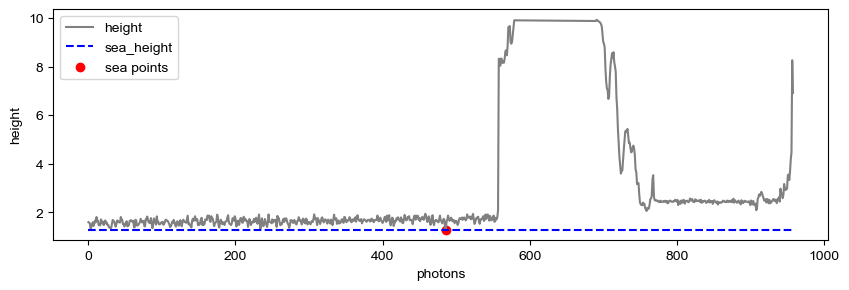

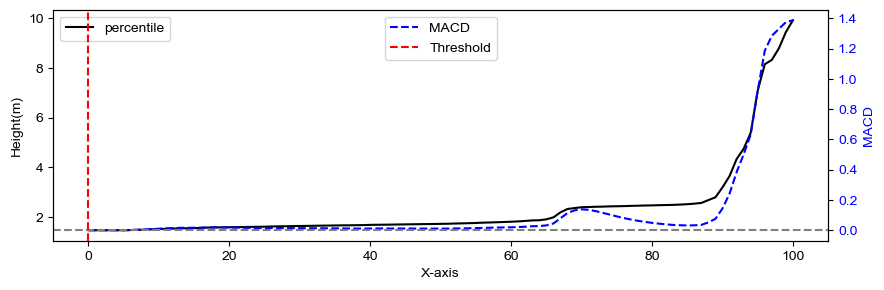

In [11]:
folder_path_03  = 'G:\ICESat-2\Region2\Region2_2019\ATL03_Region2_2019'
folder_path_08 = 'G:\ICESat-2\Region2\Region2_2019\ATL08_Region2_2019' 
# mask = [[0.273, 1.475], [51.262, 51.863]]
mask = [[-0.839, 0.382], [53.164, 53.852]]

# mask = Region_info[detect_region]['mask']

# folder_path_03  = f'H:\Region4\Region4_{year}\ATL03_Region4_{year}'
# folder_path_08 =  f'H:\Region4\Region4_{year}\ATL08_Region4_{year}' 
beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
beam = [['gt1l', 'gt1r'],['gt2l', 'gt2r'],['gt3l', 'gt3r']]
beam3 = [['gt1l', 'gt1r']]
beam = ['gt1r']
TF_height_range = [30, 70]

No = 31
ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
filepath_03 = ATL_name_group[No][0]
filepath_08 = ATL_name_group[No][1]
print(filepath_08)

Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask, TF_height_range, 30, sea_thred = -1, is_display = True)

In [12]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd
output_path = f'G:\ICESat-2\Region2_map\Henber_map\A2019/z{No}_{beam[0]}_raw.shp'
geometry = [Point(xy) for xy in zip(merged_df3['mean_lon'], merged_df3['mean_lat'])]
gdf = gpd.GeoDataFrame(merged_df3, geometry=geometry, crs='EPSG:4326')

gdf.to_file(output_path)


In [40]:
folder_path_03  = 'G:\ICESat-2\Region1\Region1_2019\ATL03_Region1_2019'
folder_path_08 = 'G:\ICESat-2\Region1\Region1_2019\ATL08_Region1_2019' 
# mask = [[0.273, 1.475], [51.262, 51.863]]
mask = [[0.273, 1.475], [51.262, 51.863]]
mask1 = [[0.7693, 0.9492], [51.3751, 51.5718]]

# mask = Region_info[detect_region]['mask']

# folder_path_03  = f'H:\Region4\Region4_{year}\ATL03_Region4_{year}'
# folder_path_08 =  f'H:\Region4\Region4_{year}\ATL08_Region4_{year}' 
beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
beam = [['gt1l', 'gt1r'],['gt2l', 'gt2r'],['gt3l', 'gt3r']]
beam3 = [['gt1l', 'gt1r']]
beam = ['gt1r']
TF_height_range = [30, 70]

No = 28
ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
filepath_03 = ATL_name_group[No][0]
filepath_08 = ATL_name_group[No][1]
filepath_08

'G:\\ICESat-2\\Region1\\Region1_2019\\ATL08_Region1_2019\\ATL08_20190822002112_08390402_006_02.h5'

In [ ]:
folder_path_03  = 'G:\ICESat-2\Region1\Region1_2019\ATL03_Region1_2019'
folder_path_08 = 'G:\ICESat-2\Region1\Region1_2019\ATL08_Region1_2019' 
# mask = [[0.273, 1.475], [51.262, 51.863]]
mask = [[0.273, 1.475], [51.262, 51.863]]
mask1 = [[0.7693, 0.9492], [51.3751, 51.5718]]

# mask = Region_info[detect_region]['mask']

# folder_path_03  = f'H:\Region4\Region4_{year}\ATL03_Region4_{year}'
# folder_path_08 =  f'H:\Region4\Region4_{year}\ATL08_Region4_{year}' 
beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
beam = [['gt1l', 'gt1r'],['gt2l', 'gt2r'],['gt3l', 'gt3r']]
beam3 = [['gt1l', 'gt1r']]
beam = ['gt1r']
TF_height_range = [30, 70]

No = 28
ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
filepath_03 = ATL_name_group[No][0]
filepath_08 = ATL_name_group[No][1]
print(filepath_08)

Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask, TF_height_range, 30, sea_thred = 0.015, is_display = True)

# merged_df3, _, _, log = icesat_gt_processing3_new(9, filepath_03, filepath_08, beam3, mask, TF_height_range, 30, sea_thred = 0.1, is_display = True)
# import geopandas as gpd
# from shapely.geometry import Point
# import pandas as pd
# output_path = f'G:\ICESat-2\Region2_map\Henber_map\A2019/test\z{No}_{beam[0]}_new.shp'
# geometry = [Point(xy) for xy in zip(merged_df3['mean_lon'], merged_df3['mean_lat'])]
# gdf = gpd.GeoDataFrame(merged_df3, geometry=geometry, crs='EPSG:4326')

# gdf.to_file(output_path)



[40, 41, 42, 43, 44, 45, 46, 47, 48, 49] indices
40 target_index
sea_height -0.5352058410644531
[-0.5352058410644531] sea_height_list
-0.5352058410644531 Final_sea_height <class 'numpy.float64'>
<class 'pandas.core.series.Series'> type mask 1101 mask len


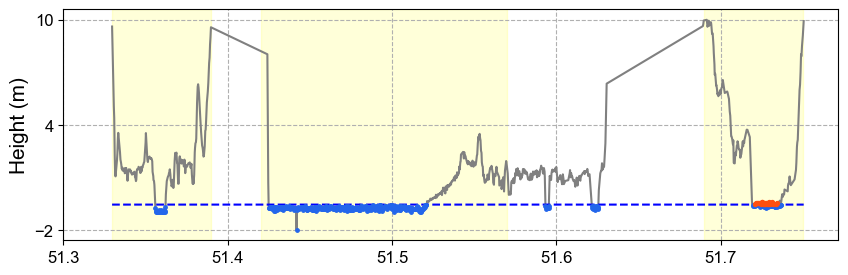

In [101]:
#---------all track----------------
Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask, TF_height_range, 30, sea_thred = 0.03, is_display = False)
Raw_df['sea_height'] = _
Raw_df['sea_point'] =  Raw_df['OH'] <= _
plt.figure(figsize=(10, 3))
plt.plot(Raw_df['mean_lat'], Raw_df['OH'], color ='gray',label = 'Land photons')
plt.plot(Raw_df['mean_lat'],  Raw_df['sea_height'], color = 'blue' , linestyle = '--', label = 'Detected Sea Height')
# plt.plot(merged_df3['sea_point'], color = 'blue' , linestyle = '--', label = 'sea_height')
threshold = _ # 你可以改
plt.scatter(
    Raw_df.loc[Raw_df['OH'] < threshold, 'mean_lat'], 
    Raw_df.loc[Raw_df['OH'] < threshold, 'OH'],
    # color="#2366EBFF", s=6, label=r'Sea points (<= Height$_{sea}$)',
    color="#2366EBFF", s=6, label=r'Removed pseudo-elevation points', 
    zorder=3
)

plt.scatter(
    Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735) , 'mean_lat'], 
    Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735), 'OH'],
    # color="#FF4F0F", s=8, label=r'Sea points (> Height$_{sea}$)',
    color="#FF4F0F", s=8, label='Residual pseudo-elevation points',
    alpha=1,
    zorder=3
)

xmin = Raw_df['mean_lat'].min()
xmax = Raw_df['mean_lat'].max()
mid = 51.39 # 前半部分的边界
plt.axvspan(xmin, mid, color='yellow', alpha=0.15, zorder=1)  # 背景阴影层
plt.axvspan(51.42, 51.57, color='yellow', alpha=0.15, zorder=1)  # 背景阴影层
plt.axvspan(51.69, 51.75, color='yellow', alpha=0.15, zorder=1)  # 背景阴影层


plt.yticks(np.arange(-2, 10.1, 6), fontsize = 12)
plt.xticks(np.arange(5130000/100000, 5180000/100000, 10000/100000), fontsize = 12)
plt.ylabel('Height (m)', fontsize = 15)
# plt.xlabel('Latitude (°)', fontsize = 15)
plt.tick_params(axis='y', labelcolor='black')
plt.ticklabel_format(style='plain', axis='x')

plt.grid(True)

# plt.legend( fontsize = 12)

# plt.legend(
#     loc='upper center',          # 放在图的上方中间
#     bbox_to_anchor=(0.5, 1.25),  # 调整距离图的垂直位置（1.15可以上下微调）
#     ncol=4,                      # 一行四列
#     frameon=False,
#     fontsize=18,
#     handlelength=2.5,              # 控制图例线条长度
#     columnspacing=0.1,             # 缩小列间距
#     handletextpad=0.4   
# )

plt.grid(linestyle='--')

In [22]:
xmin

51.32969018791365

[58, 59, 60, 61, 62, 63, 64, 65, 66, 67] indices
58 target_index
sea_height -0.6163291931152344
[-0.6163291931152344] sea_height_list
-0.6163291931152344 Final_sea_height <class 'numpy.float64'>
<class 'pandas.core.series.Series'> type mask 578 mask len


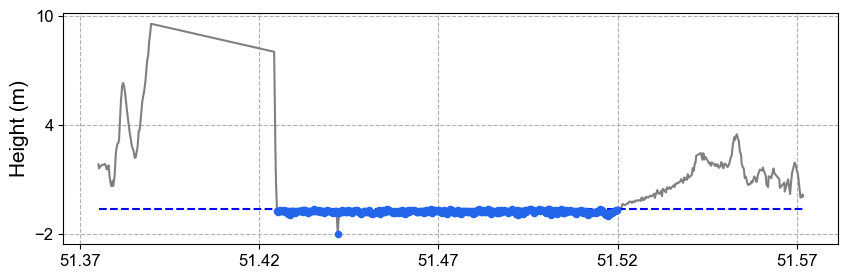

In [56]:
#---------mask1---------------
Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask1, TF_height_range, 30, sea_thred = 0.015, is_display = False)
Raw_df['sea_height'] = _
Raw_df['sea_height'] = _
Raw_df['sea_point'] =  Raw_df['OH'] <= _
plt.figure(figsize=(10, 3))
plt.plot(Raw_df['mean_lat'], Raw_df['OH'], color ='gray',label = 'Land photons')
plt.plot(Raw_df['mean_lat'],  Raw_df['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
# plt.plot(merged_df3['sea_point'], color = 'blue' , linestyle = '--', label = 'sea_height')
threshold = _ # 你可以改
plt.scatter(
    Raw_df.loc[Raw_df['OH'] < threshold, 'mean_lat'], 
    Raw_df.loc[Raw_df['OH'] < threshold, 'OH'],
    color="#2366EBFF", s=20, label=r'Sea points (<= Height$_{sea}$)',
    zorder=3
)

# plt.scatter(
#     Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735) , 'mean_lat'], 
#     Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735), 'OH'],
#     color="#E19212FF", s=20, label=r'Sea points (> Height$_{sea}$)',
#     alpha=1,
#     zorder=3
# )



plt.yticks(np.arange(-2, 10.1, 6), fontsize = 12)
plt.xticks(np.arange(5137000/100000, 5157000/100000, 5000/100000), fontsize = 12)
# plt.xticks(np.arange(5132000/100000, 5180000/100000, 10000/100000), fontsize = 12)
plt.ylabel('Height (m)', fontsize = 15)
# plt.xlabel('Latitude (°)', fontsize = 15)
plt.tick_params(axis='y', labelcolor='black')
plt.ticklabel_format(style='plain', axis='x')

plt.grid(True)
# plt.legend( fontsize = 12)
plt.grid(linestyle='--')

[10, 11, 12, 13, 14, 15, 16, 17, 18, 19] indices
10 target_index
sea_height -0.7247467041015624
[-0.7247467041015624] sea_height_list
-0.7247467041015624 Final_sea_height <class 'numpy.float64'>
<class 'pandas.core.series.Series'> type mask 222 mask len


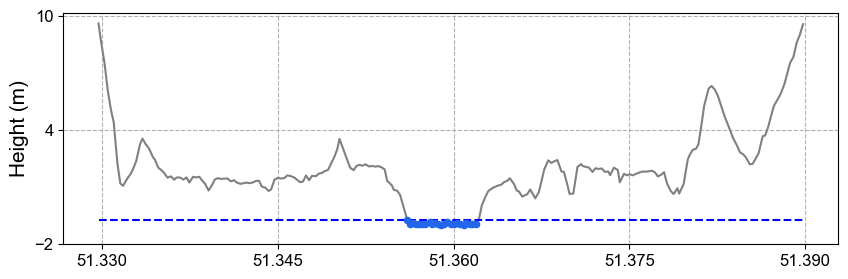

In [64]:
#---------mask2---------------
mask2 = [[0.273, 1.075], [51.3056, 51.3974]]
# mask = [[0.273, 1.475], [51.262, 51.863]]
# mask2 = [[0.273, 1.475], [51.262, 51.863]]
# mask1 = [[0.7693, 0.9492], [51.3751, 51.5718]]
Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask2, TF_height_range, 30, sea_thred = 0.015, is_display = False)
Raw_df['sea_height'] = _
Raw_df['sea_height'] = _
Raw_df['sea_point'] =  Raw_df['OH'] <= _
plt.figure(figsize=(10, 3))
plt.plot(Raw_df['mean_lat'], Raw_df['OH'], color ='gray',label = 'Land photons')
plt.plot(Raw_df['mean_lat'],  Raw_df['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
# plt.plot(merged_df3['sea_point'], color = 'blue' , linestyle = '--', label = 'sea_height')
threshold = _ # 你可以改
plt.scatter(
    Raw_df.loc[Raw_df['OH'] < threshold, 'mean_lat'], 
    Raw_df.loc[Raw_df['OH'] < threshold, 'OH'],
    color="#2366EBFF", s=20, label=r'Sea points (<= Height$_{sea}$)',
    zorder=3
)

plt.scatter(
    Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735) , 'mean_lat'], 
    Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735), 'OH'],
    color="#E19212FF", s=20, label=r'Sea points (> Height$_{sea}$)',
    alpha=1,
    zorder=3
)



plt.yticks(np.arange(-2, 10.1, 6), fontsize = 12)
plt.xticks(np.arange(5133000/100000, 5139000/100000, 1500/100000), fontsize = 12)
# 
plt.ylabel('Height (m)', fontsize = 15)
# plt.xlabel('Latitude (°)', fontsize = 15)
plt.tick_params(axis='y', labelcolor='black')
plt.ticklabel_format(style='plain', axis='x')

plt.grid(True)
# plt.legend( fontsize = 12)
plt.grid(linestyle='--')

[30, 31, 32, 33, 34, 35, 36, 37, 38, 39] indices
30 target_index
sea_height -0.46800880432128916
[-0.46800880432128916] sea_height_list
-0.46800880432128916 Final_sea_height <class 'numpy.float64'>
<class 'pandas.core.series.Series'> type mask 170 mask len


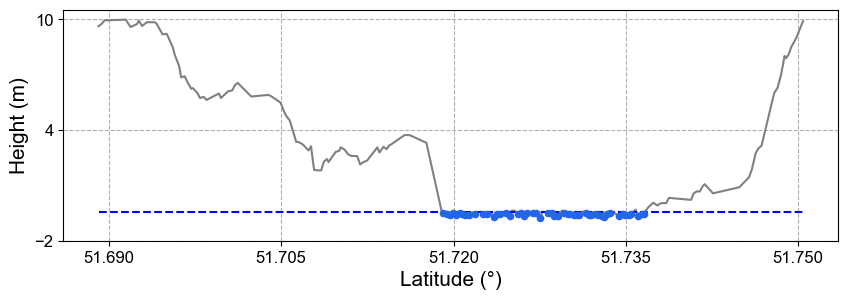

In [76]:
#---------mask3---------------
mask3 = [[0.7356, 0.891471], [51.66412,51.978633]]
# mask = [[0.273, 1.475], [51.262, 51.863]]
# mask2 = [[0.273, 1.475], [51.262, 51.863]]
# mask1 = [[0.7693, 0.9492], [51.3751, 51.5718]]
Raw_df, merged_df3, _, _, log = icesat_gt_processing(filepath_03, filepath_08, beam, mask3, TF_height_range, 30, sea_thred = 0.015, is_display = False)
Raw_df['sea_height'] = _
Raw_df['sea_height'] = _
Raw_df['sea_point'] =  Raw_df['OH'] <= _
plt.figure(figsize=(10, 3))
plt.plot(Raw_df['mean_lat'], Raw_df['OH'], color ='gray',label = 'Land photons')
plt.plot(Raw_df['mean_lat'],  Raw_df['sea_height'], color = 'blue' , linestyle = '--', label = 'sea_height')
# plt.plot(merged_df3['sea_point'], color = 'blue' , linestyle = '--', label = 'sea_height')
threshold = _ # 你可以改
plt.scatter(
    Raw_df.loc[Raw_df['OH'] < threshold, 'mean_lat'], 
    Raw_df.loc[Raw_df['OH'] < threshold, 'OH'],
    color="#2366EBFF", s=20, label=r'Sea points (<= Height$_{sea}$)',
    zorder=3
)

# plt.scatter(
#     Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735) , 'mean_lat'], 
#     Raw_df.loc[(Raw_df['OH'] > threshold)& (Raw_df['mean_lat']>51.72)& (Raw_df['mean_lat']<51.735), 'OH'],
#     color="#E19212FF", s=8, label=r'Sea points (> Height$_{sea}$)',
#     alpha=1,
#     zorder=3
# )



plt.yticks(np.arange(-2, 10.1, 6), fontsize = 12)
plt.xticks(np.arange(5169000/100000, 5175000/100000, 1500/100000), fontsize = 12)
# plt.xticks(np.arange(5132000/100000, 5180000/100000, 10000/100000), fontsize = 12)
plt.ylabel('Height (m)', fontsize = 15)
plt.xlabel('Latitude (°)', fontsize = 15)
plt.tick_params(axis='y', labelcolor='black')
plt.ticklabel_format(style='plain', axis='x')

plt.grid(True)
# plt.legend( fontsize = 12)
plt.grid(linestyle='--')

In [105]:
merged_df3['OH'][merged_df3['sea_point']]

0      9.607494
1      8.718845
2      7.550262
3      6.056374
4      5.054150
         ...   
732    8.079823
733    8.505322
734    8.904514
735    9.097557
736    9.917572
Name: OH, Length: 71, dtype: float32

In [ ]:
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd


output_path = f'G:\ICESat-2\Region1_map\Thames_map\A2020/test\z{No}_{beam[0]}.shp'
geometry = [Point(xy) for xy in zip(merged_df['mean_lon'], merged_df['mean_lat'])]
gdf = gpd.GeoDataFrame(merged_df, geometry=geometry, crs='EPSG:4326')

gdf.to_file(output_path)


In [ ]:
if __name__ == '__main__':
    

    #----------------------------------------------------------------------------------------
    #--------------------------------------Region 1 -----------------------------------------
    #2019, 
    year_list = [2019, 2020, 2021, 2022, 2023]
    # year_list = 
    Region_info = {
            'region1': {'name':'Thames'  , 'mask':[[0.273, 1.475], [51.262, 51.863]]},
            'region2': {'name':'Region1a', 'mask':[[0.803, 1.831], [52.479, 53.031]]},
            'region3': {'name':'Region1b', 'mask':[[1.007, 1.842], [51.820, 52.481]]},
            'region4': {'name':'Region1c', 'mask':[[0.518, 1.541], [50.820, 51.257]]},
        }
    detect_region = 'region3'

    print('region:' ,Region_info[detect_region]['name'])
    print('region_mask:', Region_info[detect_region]['mask'])

    region_name = Region_info[detect_region]['name']
    mask = Region_info[detect_region]['mask']
    TF_height_range = [30, 70]
    #----------------------------------------------------------------------------------------
    for j in range(len(year_list)):

        year = year_list[j]

        output_root_path = f'G:\ICESat-2\Region1\Region1_{region_name}'
        if not os.path.exists(output_root_path):
            os.makedirs(output_root_path)
            output_path = f'G:\ICESat-2\Region1\Region1_{region_name}\A_{region_name}_30m_{year}_new10.csv'
        else:
            output_path = f'G:\ICESat-2\Region1\Region1_{region_name}\A_{region_name}_30m_{year}_new10.csv'

        log_path =  f'G:\ICESat-2\Region1\Region1_{region_name}\A_log_{region_name}_{year}_new10.txt'
        

        folder_path_03  = f'G:\ICESat-2\Region1\Region1_{year}\ATL03_Region1_{year}'
        folder_path_08 =  f'G:\ICESat-2\Region1\Region1_{year}\ATL08_Region1_{year}' 
        #beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
        beam = [['gt1l', 'gt1r'], ['gt2l', 'gt2r'] ,['gt3l', 'gt3r']]
        ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
        
        output = []
        log_list = []
        
        for i in range(len(ATL_name_group)):
        # for i in range(3):
        # for i in range(20, 21):
            
            filepath_03 = ATL_name_group[i][0]
            filepath_08 = ATL_name_group[i][1]
            
            merged_df, _, _, log = icesat_gt_processing3_new(i, filepath_03, filepath_08, beam, mask, TF_height_range,  30, sea_thred = 0.05, is_display = False)
            
            if merged_df.empty:
                continue
            
            print('------------------------------------')
            output.append(merged_df)
            print('No_'+str(i) + '_' + str(filepath_03) + ' is done')
            print(str(round(i*100/len(ATL_name_group), 2))+ '%' + ' is done')
            log.append('No_'+str(i) + ': ' + str(filepath_03) + '\n')
            log_list.append(log)
         #-----------------------------output log info-------------------------------------- 
        
        with open(log_path, "w") as file:
            for logs in log_list:
                for log in logs:
                    file.write(log)
        #-------------------------- output result-------------------------------------------
              
        output = pd.concat(output, ignore_index=True) 
        print('output_len: ',len(output))
        print(output[:10])
        output.to_csv(output_path)


region: Region1a
region_mask: [[0.803, 1.831], [52.479, 53.031]]
[77, 78, 79, 80, 81, 82, 83, 84, 85, 86] indices
77 target_index
[72, 73, 74, 75, 76, 77, 78, 79, 80, 81] indices
72 target_index
<class 'pandas.core.series.Series'> type mask 770 mask len
<class 'pandas.core.series.Series'> type mask 742 mask len
[97, 98, 99, 100] indices
100 target_index
[98, 99, 100] indices
100 target_index
<class 'pandas.core.series.Series'> type mask 540 mask len
G:\ICESat-2\Region1\Region1_2019\ATL03_Region1_2019\ATL03_20190104234026_01150206_006_02.h5_gt2lgt2r is empty
<class 'pandas.core.series.Series'> type mask 520 mask len
G:\ICESat-2\Region1\Region1_2019\ATL03_Region1_2019\ATL03_20190104234026_01150206_006_02.h5_gt2lgt2r is empty
[] indices
100 target_index
[100] indices
100 target_index
<class 'pandas.core.series.Series'> type mask 312 mask len
G:\ICESat-2\Region1\Region1_2019\ATL03_Region1_2019\ATL03_20190104234026_01150206_006_02.h5_gt3lgt3r is empty
<class 'pandas.core.series.Series'> typ

In [5]:
#--------------------------------------Region 3 -----------------------------------------

if __name__ == '__main__':
    

    #----------------------------------------------------------------------------------------

    year_list = [2019, 2020, 2021, 2022, 2023]
    # year_list = [2024]
    Region_info = {
            'region1': {'name':'Region3a1', 'mask':[[-2.523, -1.644], [56.661, 57.774]]},
            'region2': {'name':'Region3b1'  , 'mask':[[-2.494, -1.366], [55.380, 56.062]]},
            'region3': {'name':'Region3b2', 'mask':[[-1.670, -0.901], [54.517, 55.3723]]},
            'region4': {'name':'Region3c', 'mask':[[-2.469, -0.909], [50.473, 50.884]]},
        }
    detect_region = 'region3'

    print('region:' ,Region_info[detect_region]['name'])
    print('region_mask:', Region_info[detect_region]['mask'])

    region_name = Region_info[detect_region]['name']
    mask = Region_info[detect_region]['mask']
    TF_height_range = [30, 70]
    #----------------------------------------------------------------------------------------
    for j in range(len(year_list)):

        year = year_list[j]

        output_root_path = f'G:\ICESat-2\Region3\Region3_{region_name}'
        if not os.path.exists(output_root_path):
            os.makedirs(output_root_path)
            output_path = f'G:\ICESat-2\Region3\Region3_{region_name}\A_{region_name}_30m_{year}_new10.csv'
        else:
            output_path = f'G:\ICESat-2\Region3\Region3_{region_name}\A_{region_name}_30m_{year}_new10.csv'

        log_path =  f'G:\ICESat-2\Region3\Region3_{region_name}\A_log_{region_name}_{year}_new10.txt'
        

        folder_path_03  = f'G:\ICESat-2\Region3\Region3_{year}\ATL03_Region3_{year}'
        folder_path_08 =  f'G:\ICESat-2\Region3\Region3_{year}\ATL08_Region3_{year}' 
        beam = ['gt1l', 'gt2l', 'gt3l', 'gt1r', 'gt2r', 'gt3r']
        beam = [['gt1l', 'gt1r'], ['gt2l', 'gt2r'] ,['gt3l', 'gt3r']]

        ATL_name_group = get_atl_group(folder_path_03, folder_path_08)
        
        output = []
        log_list = []
        for i in range(len(ATL_name_group)):
        # for i in range(3):
        # for i in range(1,2):
            
            filepath_03 = ATL_name_group[i][0]
            filepath_08 = ATL_name_group[i][1]
            
            merged_df, _, _, log = icesat_gt_processing3_new(i, filepath_03, filepath_08, beam, mask, TF_height_range,  30, sea_thred = 0.05, is_display = False)
            
            if merged_df.empty:
                continue
            
            print('------------------------------------')
            output.append(merged_df)
            print('No   _'+str(i) + '_' + str(filepath_03) + ' is done')
            print(str(round(i*100/len(ATL_name_group), 2))+ '%' + ' is done')
            log.append('No_'+str(i) + ': ' + str(filepath_03) + '\n')
            log_list.append(log)
         #-----------------------------output log info-------------------------------------- 
        
        with open(log_path, "w") as file:
            for logs in log_list:
                for log in logs:
                    file.write(log)
        #-------------------------- output result-------------------------------------------
              
        output = pd.concat(output, ignore_index=True) 
        print('output_len: ',len(output))
        print(output[:10])
        output.to_csv(output_path)

region: Region3b2
region_mask: [[-1.67, -0.901], [54.517, 55.3723]]
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
photon less than 200!
[97, 98, 99, 100] indices
100 target_index
[98, 99, 100] indices
100 target_index
<class 'pandas.core.series.Series'> type mask 2829 mask len
G:\ICESat-2\Region3\Region3_2019\ATL03_Region3_2019\ATL03_20190120230702_03590206_006_02.h5_gt1lgt1r is empty
<class 'pandas.core.series.Series'> type mask 2828 mask len
G:\ICESat-2\Region3\Region3_2019\ATL03_Region3_2019\ATL03_20190120230702_03590206_006_02.h5_